(301, 9) | Missing: 0 | Duplicates: 2


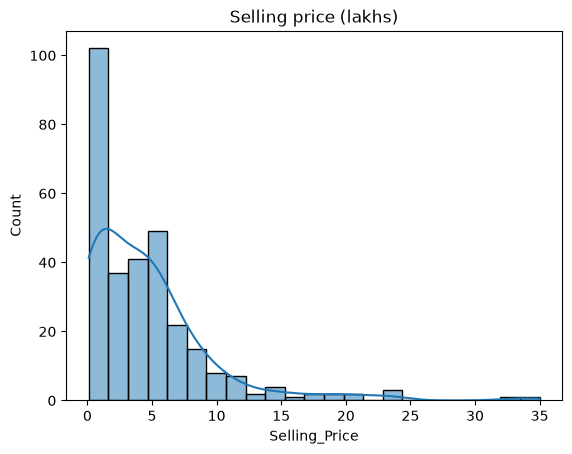

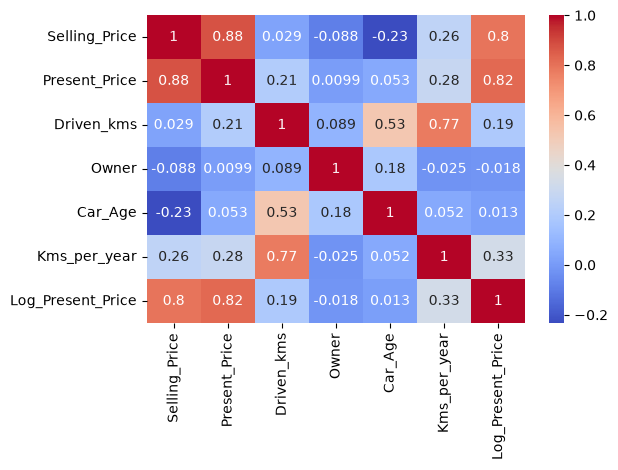

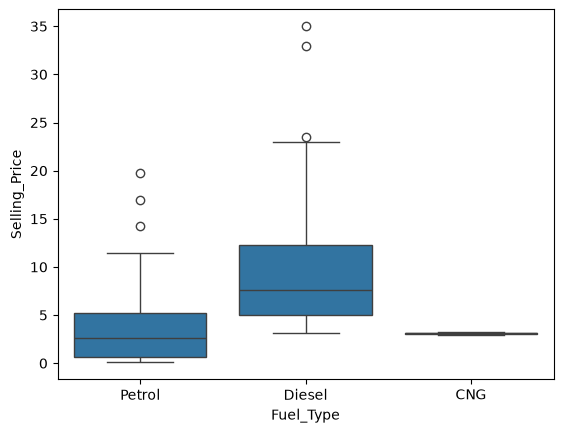

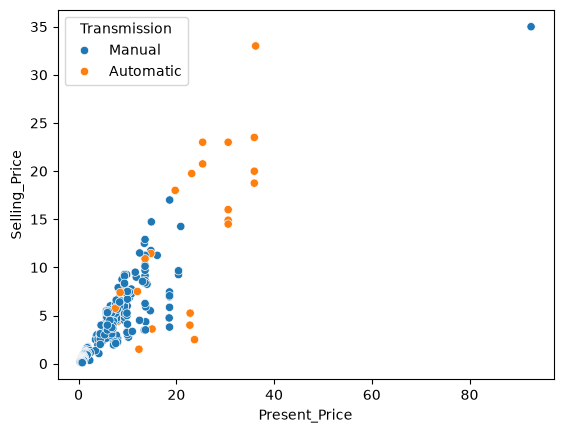

            Model  CV R2 (log)  Test R2  MAE (lakhs)  RMSE (lakhs)
            Ridge     0.966947 0.908713     0.885996      1.533872
           Linear     0.967718 0.906147     0.899554      1.555281
Gradient Boosting     0.971294 0.816549     1.025280      2.174426
    Random Forest     0.971874 0.637511     1.326649      3.056556

Best params: {'m__alpha': 0.1}
Final Ridge -> R2: 0.9065 | MAE: 0.898 lakhs | RMSE: 1.553 lakhs


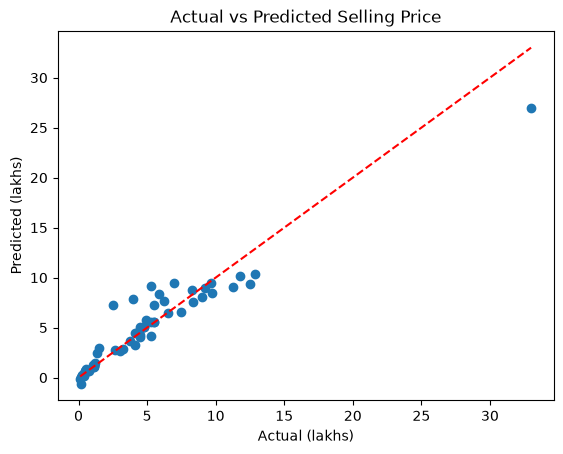

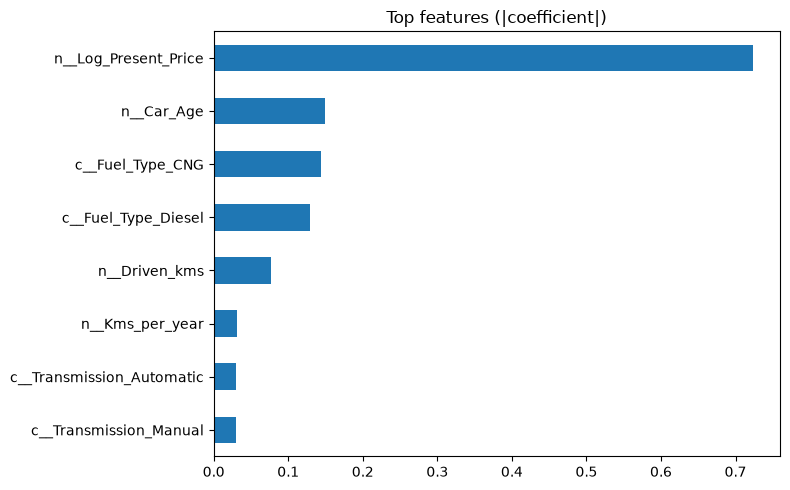

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Load data (prices are in lakhs)
df = pd.read_csv("car_data.csv")
print(df.shape, "| Missing:", df.isna().sum().sum(), "| Duplicates:", df.duplicated().sum())
df = df.drop_duplicates()

# Feature engineering
df["Car_Age"] = df["Year"].max() + 1 - df["Year"]
df["Kms_per_year"] = df["Driven_kms"] / df["Car_Age"]
df["Log_Present_Price"] = np.log1p(df["Present_Price"])
df = df.drop(columns=["Car_Name", "Year"])

# EDA
sns.histplot(df["Selling_Price"], kde=True); plt.title("Selling price (lakhs)"); plt.show()
sns.heatmap(df.select_dtypes("number").corr(), annot=True, cmap="coolwarm"); plt.tight_layout(); plt.show()
sns.boxplot(data=df, x="Fuel_Type", y="Selling_Price"); plt.show()
sns.scatterplot(data=df, x="Present_Price", y="Selling_Price", hue="Transmission"); plt.show()

# Preprocessing
X, y = df.drop(columns="Selling_Price"), np.log1p(df["Selling_Price"])
cat = X.select_dtypes(exclude="number").columns.tolist()
num = X.select_dtypes("number").columns.tolist()
pre = ColumnTransformer([("c", OneHotEncoder(handle_unknown="ignore"), cat), ("n", StandardScaler(), num)])
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

# Compare models
models = {
    "Linear": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(300, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}
rows = []
for n, m in models.items():
    pipe = Pipeline([("pre", pre), ("m", m)])
    cv = cross_val_score(pipe, X_tr, y_tr, cv=5, scoring="r2").mean()
    pipe.fit(X_tr, y_tr)
    p = np.expm1(pipe.predict(X_te)); a = np.expm1(y_te)
    rows.append([n, cv, r2_score(a, p), mean_absolute_error(a, p), np.sqrt(mean_squared_error(a, p))])
res = pd.DataFrame(rows, columns=["Model", "CV R2 (log)", "Test R2", "MAE (lakhs)", "RMSE (lakhs)"]).sort_values("Test R2", ascending=False)
print(res.to_string(index=False))

# Final model: Ridge (trees cannot extrapolate to the few expensive cars)
gs = GridSearchCV(Pipeline([("pre", pre), ("m", Ridge())]),
                  {"m__alpha": [0.01, 0.1, 1, 3, 10, 30]}, cv=5, scoring="r2").fit(X_tr, y_tr)
best = gs.best_estimator_
p = np.expm1(best.predict(X_te)); a = np.expm1(y_te)
print("\nBest params:", gs.best_params_)
print(f"Final Ridge -> R2: {r2_score(a, p):.4f} | MAE: {mean_absolute_error(a, p):.3f} lakhs | RMSE: {np.sqrt(mean_squared_error(a, p)):.3f} lakhs")

plt.scatter(a, p); plt.plot([a.min(), a.max()], [a.min(), a.max()], "r--")
plt.xlabel("Actual (lakhs)"); plt.ylabel("Predicted (lakhs)"); plt.title("Actual vs Predicted Selling Price"); plt.show()

names = best.named_steps["pre"].get_feature_names_out()
imp = pd.Series(best.named_steps["m"].coef_, index=names).abs().sort_values().tail(8)
imp.plot.barh(figsize=(8, 5), title="Top features (|coefficient|)"); plt.tight_layout(); plt.show()
